# 15 — Readings on the wrong shot, the fix, and how sure we are

1. **Alignment.** `extract_features.py` puts the lab meter and the RF readings one *row* earlier. On the full runs
   that is often not the right *pulse*: 35–40 % of the rows of the high-charge segments skip pulses, and the PC reads a
   shot 0.4–4.8 s after its trigger, so the meter sometimes already holds this pulse. `scripts/meter_alignment.py`
   moves every reading to its own pulse with the rules of `pulses.py` (meter: previous pulse if read < 2.2 s after the
   trigger; RF: its own stamp − 1) → `results/datasets_aligned/`.
2. **What it changes** for the same-shot models and for forecasting (the h = 1 leak).
3. **Significance** (circular block bootstrap) and **heteroscedastic intervals** (`scripts/uncertainty_regimes.py`).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parents[1] if Path.cwd().name == "adnan" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from regimes import load, score, REGIMES, NOISE_FLOOR_PCT
R = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
REG_COL = {"low": "tab:blue", "high_rep": "tab:orange", "high_nonrep": "tab:green"}
SEG_ORDER = [0, 3, 4, 5, 1, 6, 7]
def segcols(df):
    return [c for c in SEG_ORDER if c in set(df.columns.get_level_values(-1))]

In [2]:
al = json.loads((R / "datasets_aligned/alignment.json").read_text())
pd.DataFrame({s: {"rows not 1 pulse apart": v["rows_not_one_pulse_apart"],
                  "lab: share read late (same pulse)": v["lab_laser_power"]["shift_share"]["0"],
                  "lab: moved vs results/datasets": v["lab_laser_power"]["changed_vs_dataset"],
                  "PGLA: moved vs results/datasets": v["PGLA_drop"]["changed_vs_dataset"],
                  "lab: rows with own reading": v["lab_laser_power"]["rows_with_reading"]}
              for s, v in al.items()}).T.round(2)

,rows not 1 pulse apart,lab: share read late (same pulse),lab: moved vs results/datasets,PGLA: moved vs results/datasets,lab: rows with own reading
0,0.00,0.00,0.00,0.00,1.00
1,0.35,0.42,0.45,0.26,0.89
2,0.00,0.00,0.00,0.00,1.00
3,0.01,0.01,0.01,0.02,0.99
4,0.28,0.43,0.47,0.41,0.76
5,0.41,0.47,0.50,0.30,0.89
6,0.00,0.00,0.00,0.00,1.00
7,0.35,0.50,0.70,0.45,0.68


**Reading.** Segments 0, 2, 3 and 6 were fine (no skipped pulses, meter read early). On segments 1, 4, 5 and 7,
**45–70 % of the lab readings and 26–45 % of the PGLA readings were on the wrong shot** in `results/datasets`.

Check against the camera (on its own pulse, not the target): in each read-delay bin, the correlation of the raw lab
reading's jitter with the camera of the same pulse and of the previous pulse (training part).

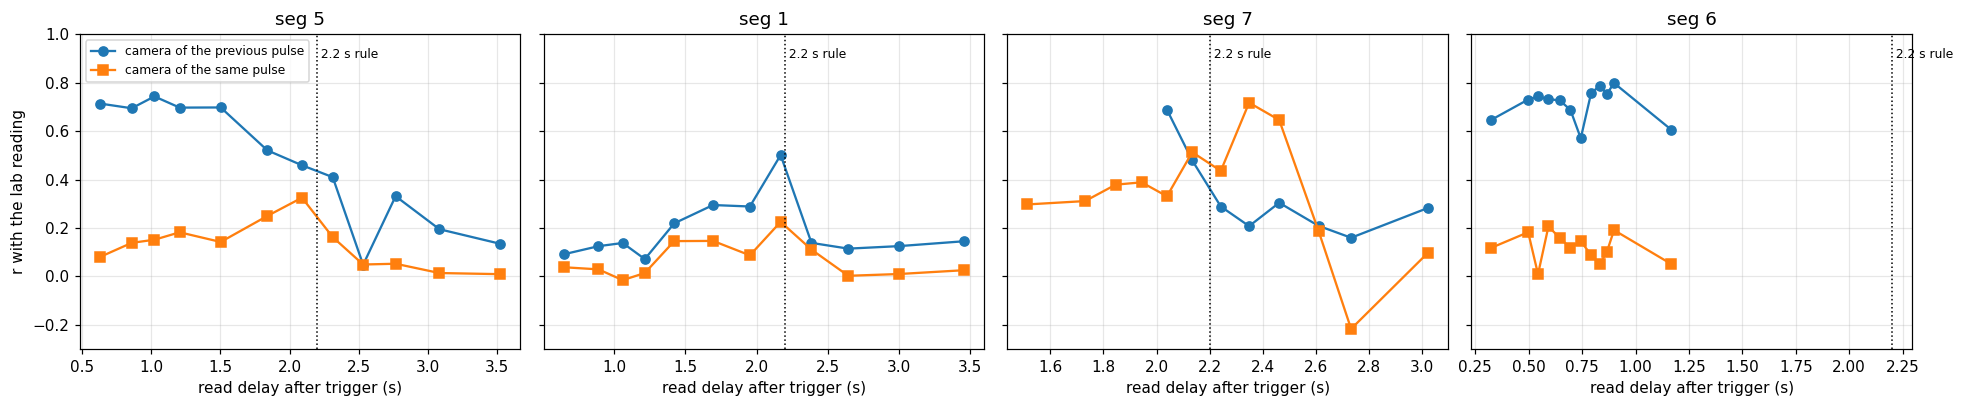

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, s in zip(axes, ["5", "1", "7", "6"]):
    b = pd.DataFrame(al[s]["lab_laser_power"]["camera_check_bins"])
    mid = np.clip((b.lo.replace(-np.inf, b.hi.min() - 0.3) + b.hi.replace(np.inf, b.lo.max() + 0.5)) / 2, 0, 6)
    ax.plot(mid, b.r_prev, "o-", label="camera of the previous pulse")
    ax.plot(mid, b.r_same, "s-", label="camera of the same pulse")
    ax.axvline(2.2, color="k", ls=":", lw=1); ax.text(2.2, 0.9, " 2.2 s rule", fontsize=8)
    ax.set_title(f"seg {s}"); ax.set_xlabel("read delay after trigger (s)")
axes[0].set_ylabel("r with the lab reading"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.3, 1)
fig.tight_layout(); plt.show()

In [4]:
rows = []
for tag, path in (("results/datasets", "results/datasets"), ("aligned", "results/datasets_aligned")):
    segs, names = load(R.parent / path, robust=5)
    for s in SEG_ORDER:
        g = segs[s]; j = g["jitter"]; m = g["good"] & np.isfinite(j)
        for f in ("lab_laser_power", "PGLA_drop"):
            x = g["Xfast"][:, names.index(f)]
            for k in (0, 1):
                a = np.r_[np.zeros(k), x[: len(x) - k]]; mm = m & (a != 0)
                rows.append({"data": tag, "segment": s, "feature": f, "row": "t" if k == 0 else "t-1",
                             "r": np.corrcoef(j[mm], a[mm])[0, 1]})
pd.DataFrame(rows).pivot_table(index=["feature", "data"], columns=["segment", "row"], values="r").round(2)

segment                              0           1           3           4  \
row                                  t   t-1     t   t-1     t   t-1     t   
feature         data                                                         
PGLA_drop       aligned           0.02  0.00  0.18  0.03  0.02  0.00  0.01   
                results/datasets  0.02  0.00  0.11  0.08  0.01  0.01 -0.00   
lab_laser_power aligned           0.33  0.08  0.66  0.23  0.19  0.05  0.17   
                results/datasets  0.33  0.08  0.51  0.43  0.19  0.05  0.10   

segment                                    5           6           7        
row                                t-1     t   t-1     t   t-1     t   t-1  
feature         data                                                        
PGLA_drop       aligned           0.04  0.14  0.07  0.16  0.04  0.35  0.12  
                results/datasets  0.00  0.06  0.07  0.16  0.04  0.17  0.21  
lab_laser_power aligned           0.08  0.30  0.10  0.86  0.19  0.65  0.21  
                results/datasets  0.14  0.17  0.18  0.86  0.19  0.34  0.56

**Reading.** After alignment the lab meter follows the charge jitter of its own shot much better (seg 7: 0.34 → 0.65,
seg 1: 0.51 → 0.66, seg 5: 0.17 → 0.30) and the excess on row t − 1 is gone (seg 7: 0.56 → 0.21, the ordinary
autocorrelation level also seen on seg 6, which was right all along).

## 2. Same-shot models on the aligned data

All nine families, robust preparation, level filter chosen on validation (now robust EMA, half-life 50 on seg 5,
25 elsewhere).

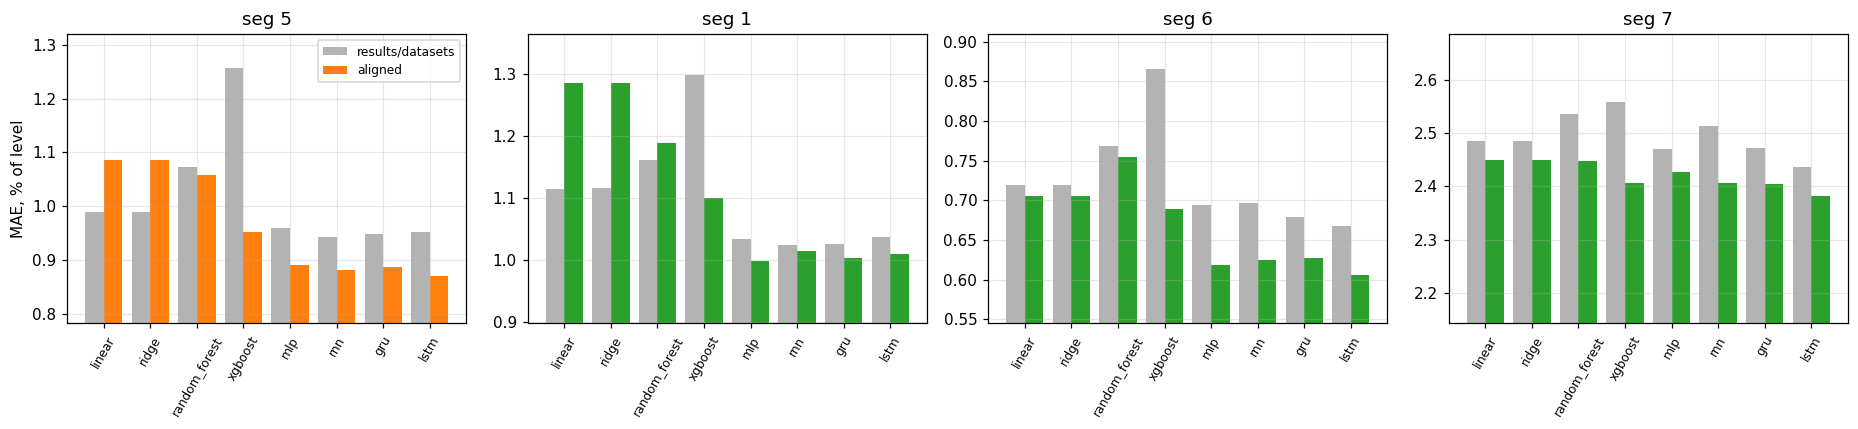

results/datasets                                     aligned  \
segment                      0     3     4     5     1     6     7       0   
model                                                                        
linear                    3.82  6.89  8.26  0.99  1.12  0.72  2.48    3.82   
ridge                     3.83  6.89  8.25  0.99  1.12  0.72  2.48    3.83   
random_forest             3.93  6.95  8.07  1.07  1.16  0.77  2.54    3.91   
xgboost                   3.92  6.93  8.02  1.26  1.30  0.87  2.56    3.89   
mlp                       3.78  6.87  8.14  0.96  1.03  0.69  2.47    3.77   
rnn                       3.78  6.98  8.11  0.94  1.02  0.70  2.51    3.78   
gru                       3.82  6.98  8.14  0.95  1.03  0.68  2.47    3.82   
lstm                      3.81  6.91  8.11  0.95  1.04  0.67  2.44    3.80   

                                                   
segment           3     4     5     1     6     7  
model                                              
linear         6.88  8.20  1.09  1.29  0.71  2.45  
ridge          6.88  8.19  1.09  1.29  0.71  2.45  
random_forest  6.92  8.00  1.06  1.19  0.75  2.45  
xgboost        6.95  7.96  0.95  1.10  0.69  2.41  
mlp            6.88  8.13  0.89  1.00  0.62  2.43  
rnn            6.94  8.09  0.88  1.01  0.63  2.41  
gru            6.96  8.07  0.89  1.00  0.63  2.40  
lstm           6.90  8.05  0.87  1.01  0.61  2.38

In [5]:
def bench(path):
    d = pd.read_csv(path); d = d[(d.framing == "jitter") & (d.pool == "regime")]
    return d.pivot_table(index="model", columns="segment", values="mae_pct")
old, new = bench(R / "regime_bench_robust_filters/scores.csv"), bench(R / "aligned/regime_bench/scores.csv")
models = ["linear", "ridge", "random_forest", "xgboost", "mlp", "rnn", "gru", "lstm"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, s in zip(axes, [5, 1, 6, 7]):
    x = np.arange(len(models))
    ax.bar(x - 0.2, old.loc[models, s], 0.4, color="0.7", label="results/datasets")
    ax.bar(x + 0.2, new.loc[models, s], 0.4, color=REG_COL[rob_reg] if (rob_reg := {5: "high_rep"}.get(s, "high_nonrep")) else None, label="aligned")
    ax.set_xticks(x, models, rotation=60, fontsize=8); ax.set_title(f"seg {s}"); ax.set_ylim(min(new.loc[models, s].min(), old.loc[models, s].min()) * 0.9)
axes[0].set_ylabel("MAE, % of level"); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()
pd.concat({"results/datasets": old.loc[models, SEG_ORDER], "aligned": new.loc[models, SEG_ORDER]}, axis=1).round(2)

The nonlinear models improve at high charge (GRU seg 5 0.95 → 0.89 %, XGBoost 1.26 → 0.95 %), but the linear ones
get *worse* on segs 1 and 5. Now that the lab meter carries its real signal, its relation to the charge is curved,
and a straight line misfits it. A quadratic ridge shows it:

In [6]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from decompose import causal, f_robust_ema
f25 = causal(lambda x: f_robust_ema(x, 25))
rows = []
for tag, path in (("results/datasets", "results/datasets"), ("aligned", "results/datasets_aligned")):
    segs, names = load(R.parent / path, robust=5, fast_filter={r: f25 for r in REGIMES})
    for s in (5, 1, 7, 6, 0):
        g = segs[s]; X = np.c_[g["Xfast"], g["missing"]]; t = np.nan_to_num(g["jitter"])
        for nm, model in (("linear ridge", make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13)))),
                          ("quadratic ridge", make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(),
                                                            RidgeCV(alphas=np.logspace(-2, 4, 13))))):
            m = model.fit(X[g["fit"]], t[g["fit"]])
            rows.append({"data": tag, "model": nm, "segment": s, "mae_pct": score(g, np.exp(g["level"] + m.predict(X)))["mae_pct"]})
q = pd.DataFrame(rows).pivot_table(index=["data", "model"], columns="segment", values="mae_pct")[[0, 5, 1, 6, 7]]
q.loc[("aligned", "GRU (bench)"), :] = new.loc["gru", [0, 5, 1, 6, 7]].values
q.round(2)

segment                              0     5     1     6     7
data             model                                        
aligned          linear ridge     3.85  1.08  1.28  0.68  2.37
                 quadratic ridge  3.94  0.88  1.04  0.62  2.21
results/datasets linear ridge     3.87  0.99  1.13  0.68  2.36
                 quadratic ridge  3.82  1.00  1.06  0.58  2.45
aligned          GRU (bench)      3.82  0.89  1.00  0.63  2.40

**Reading.** On the aligned data a quadratic ridge (one model per segment, seconds to fit) reaches 0.88 % on seg 5 and
2.21 % on seg 7, as good as or better than the GRU; on seg 1 it is level with it. The GRU's edge at high charge was the
curvature, not memory. Low charge (seg 0) is unchanged.

## 3. Forecasting on the aligned data: the leak test

`feature_forecast.py --no-late-fix` on `results/datasets_aligned`: the lab / PGLA columns on their own row, no
workaround. If the gain at h = 1 is not larger than at h = 2–3, nothing from shot t is in the inputs.

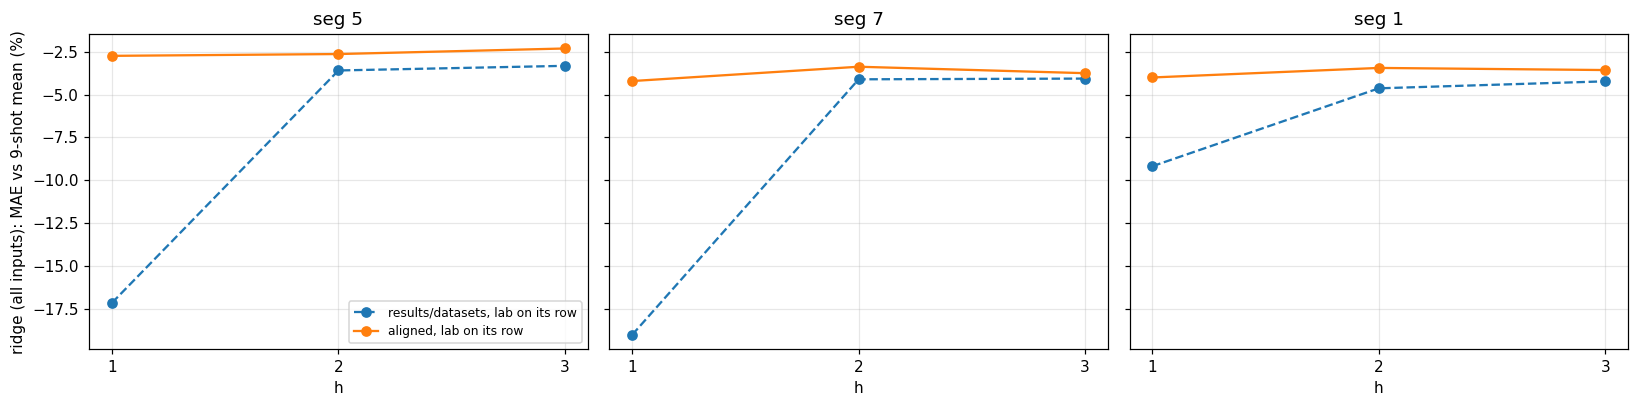

In [7]:
fa = pd.read_csv(R / "aligned/feature_forecast/scores.csv")
leak = pd.read_csv(R / "feature_forecast_leak/scores.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, s in zip(axes, (5, 7, 1)):
    for d, tag, ls in ((leak, "results/datasets, lab on its row", "--"), (fa[fa.h <= 3], "aligned, lab on its row", "-")):
        qq = d[(d.segment == s) & (d.model == "ridge, all")].sort_values("h")
        ax.plot(qq.h, qq.vs_baseline_pct, ls, marker="o", label=tag)
    ax.set_title(f"seg {s}"); ax.set_xticks([1, 2, 3]); ax.set_xlabel("h")
axes[0].set_ylabel("ridge (all inputs): MAE vs 9-shot mean (%)"); axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. Are the gains real? Circular block bootstrap (50-shot blocks, 2000 resamples)

95 % intervals of the % MAE reduction on the test shots. "ns": the interval contains 0.

In [8]:
sig = pd.read_csv(R / "aligned/uncertainty/significance.csv")
sig["cell"] = sig.apply(lambda r: f"{r.gain_pct:+.1f} [{r.lo95:+.1f}, {r.hi95:+.1f}]" + ("" if r.significant else " ns"), axis=1)
sig[sig.task == "same shot"].pivot(index="comparison", columns="segment", values="cell")[[s for s in SEG_ORDER if s in set(sig.segment)]]

segment,0,3,4,5,1,6,7
comparison,,,,,,,
gp vs ridge,"-0.5 [-2.6, +1.6] ns","-0.9 [-3.3, +1.3] ns","+3.1 [+0.2, +6.2]","+16.5 [+13.6, +19.3]","+17.1 [+13.9, +20.2]","+3.1 [-2.5, +7.4] ns","+3.8 [+0.2, +13.7]"
gru vs ridge,"+0.2 [-1.3, +1.9] ns","-1.1 [-2.9, +0.5] ns","+1.6 [-1.0, +3.9] ns","+18.3 [+15.6, +21.2]","+21.9 [+18.3, +25.9]","+11.0 [+6.6, +15.4]","+1.9 [-0.9, +9.8] ns"
mean_ensemble vs gru,"+0.3 [-0.8, +1.2] ns","+1.1 [+0.3, +2.2]","+0.7 [-0.9, +2.2] ns","-2.4 [-4.3, -0.7]","-4.6 [-6.4, -3.1]","-2.6 [-5.7, +0.3] ns","+1.2 [+0.1, +3.8]"
ridge vs level_only,"+47.4 [+43.8, +51.5]","+27.6 [+21.2, +34.2]","+26.1 [+18.4, +33.8]","+59.4 [+56.7, +61.8]","+57.6 [+54.3, +60.6]","+67.4 [+61.4, +71.8]","+36.8 [+20.0, +61.0]"
ridge+gru vs ridge,"+0.5 [-0.3, +1.2] ns","+0.1 [-0.4, +0.7] ns","+0.2 [-0.6, +1.0] ns","+16.4 [+13.8, +19.2]","+21.9 [+18.2, +25.7]","+11.4 [+6.2, +16.6]","+1.3 [-1.5, +8.7] ns"


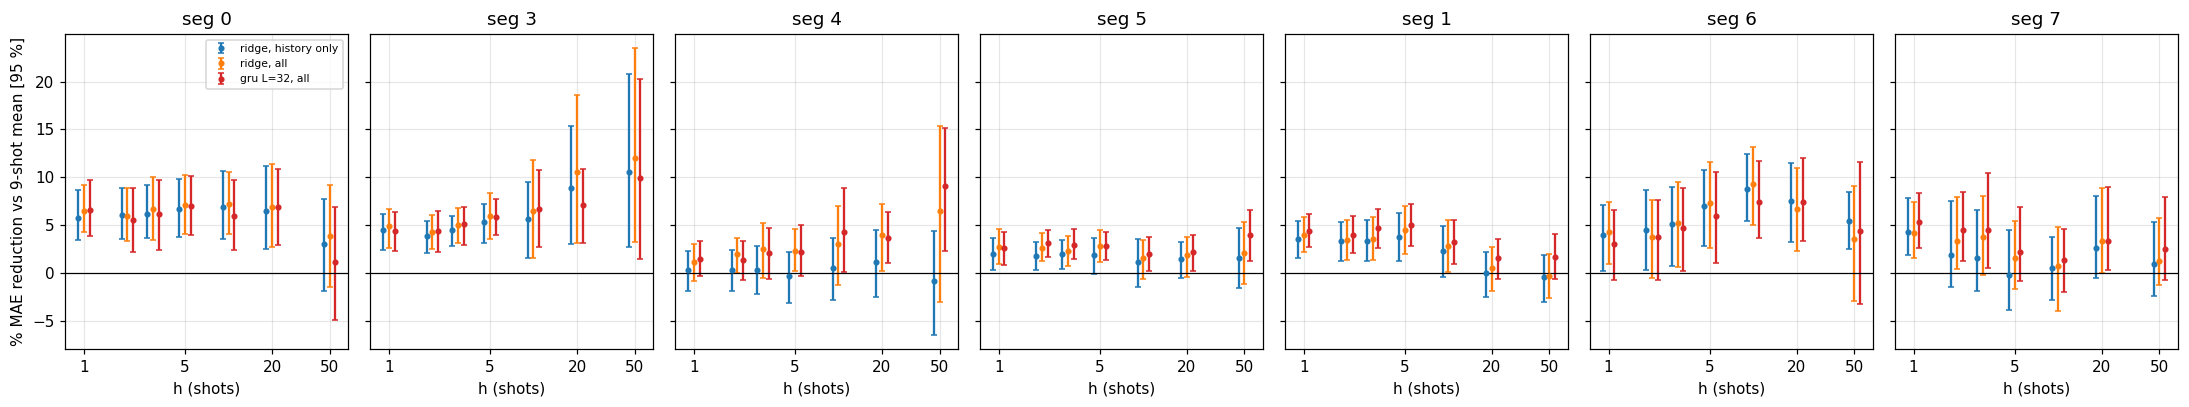

comparison
gru L=32, all vs mean9          0.73
ridge, all vs mean9             0.65
ridge, history only vs mean9    0.57
xgboost, all vs mean9           0.73
Name: share of (segment, h) significant, dtype: float64

In [9]:
f = sig[sig.task == "forecast"]
fig, axes = plt.subplots(1, 7, figsize=(20, 3.8), sharey=True)
for ax, s in zip(axes, SEG_ORDER):
    for k, (mname, c) in enumerate((("ridge, history only vs mean9", "tab:blue"), ("ridge, all vs mean9", "tab:orange"),
                                     ("gru L=32, all vs mean9", "tab:red"))):
        qq = f[(f.segment == s) & (f.comparison == mname)].sort_values("h")
        x = np.log10(qq.h) + (k - 1) * 0.04
        ax.errorbar(x, qq.gain_pct, yerr=[qq.gain_pct - qq.lo95, qq.hi95 - qq.gain_pct], fmt="o", ms=3, color=c,
                    label=mname.replace(" vs mean9", ""), capsize=2)
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(np.log10([1, 5, 20, 50]), [1, 5, 20, 50]); ax.set_title(f"seg {s}")
    ax.set_xlabel("h (shots)")
axes[0].set_ylabel("% MAE reduction vs 9-shot mean [95 %]"); axes[0].legend(fontsize=7)
fig.tight_layout(); plt.show()
f.groupby("comparison").significant.mean().round(2).rename("share of (segment, h) significant")

**Reading.**
- **Same shot:** after robust preparation the shot's own readings cut the error by 26–67 % against the level alone,
  significant everywhere. At high charge the GRU / GP beat the linear ridge by 11–22 % (segs 1, 5, 6), significantly;
  at low charge they are indistinguishable. The equal-weight ensemble is not better than the GRU at high charge.
- **Forecast:** the 9-shot mean is beaten significantly on most segments up to h ≈ 10–20 (5–7 of 7 at h = 1–3);
  seg 4 (0.1 nC, 14 % jitter) is the exception. The instruments add ~0.5–1 point over the BCM history; their
  intervals overlap with the history-only ridge's. At h = 50 most gains are no longer significant.

## 5. Error bars that follow the jitter

90 % intervals on the test shots. *Constant*: split-conformal quantiles of the validation errors. *Scaled*: those
quantiles normalised by σ_t, the robust spread of the last 200 errors known at prediction time (shots ≤ t − h).
Coverage on the calm and noisy halves of the test shots (by σ_t) shows whether the width follows the conditions.

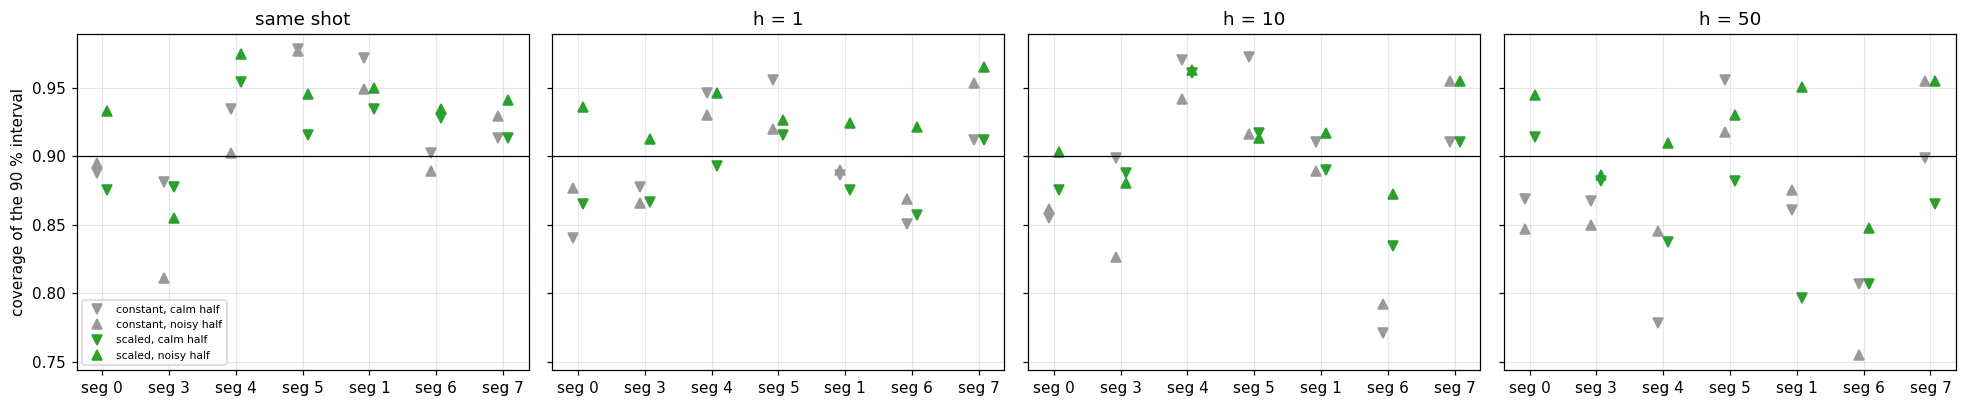

,constant cover,scaled cover,constant width %,scaled width %,constant |cover-0.9|,scaled |cover-0.9|
case,,,,,,
h = 1,0.898,0.908,23.123,23.763,0.033,0.014
h = 10,0.891,0.906,23.631,25.039,0.047,0.027
h = 2,0.901,0.920,23.325,24.830,0.036,0.022
h = 20,0.888,0.904,23.921,25.930,0.037,0.018
h = 3,0.900,0.918,23.640,24.689,0.033,0.024
h = 5,0.899,0.908,23.703,24.408,0.036,0.022
h = 50,0.863,0.886,24.108,27.347,0.055,0.027
same shot,0.916,0.923,15.307,16.403,0.035,0.033


In [10]:
iv = pd.read_csv(R / "aligned/uncertainty/intervals.csv")
iv["case"] = np.where(iv.task == "same shot", "same shot", "h = " + iv.h.astype(int).astype(str))
show = iv[iv.case.isin(["same shot", "h = 1", "h = 10", "h = 50"])]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, (case, d) in zip(axes, show.groupby("case", sort=False)):
    d = d.set_index("segment").loc[[s for s in SEG_ORDER if s in d.segment.values]]
    x = np.arange(len(d))
    for k, (tag, c) in enumerate((("constant", "0.6"), ("scaled", "tab:green"))):
        ax.plot(x + (k - 0.5) * 0.15, d[f"{tag} cover calm"], "v", color=c, label=f"{tag}, calm half")
        ax.plot(x + (k - 0.5) * 0.15, d[f"{tag} cover noisy"], "^", color=c, label=f"{tag}, noisy half")
    ax.axhline(0.9, color="k", lw=0.8); ax.set_xticks(x, [f"seg {s}" for s in d.index]); ax.set_title(case)
axes[0].set_ylabel("coverage of the 90 % interval"); axes[0].legend(fontsize=7)
fig.tight_layout(); plt.show()
summary = iv.groupby("case")[["constant cover", "scaled cover", "constant width %", "scaled width %"]].mean()
summary["constant |cover-0.9|"] = iv.assign(e=(iv["constant cover"] - 0.9).abs()).groupby("case").e.mean()
summary["scaled |cover-0.9|"] = iv.assign(e=(iv["scaled cover"] - 0.9).abs()).groupby("case").e.mean()
summary.round(3)

**Reading.** Scaling by the recent error spread brings the coverage closer to 90 % on average and, for the same-shot
model, makes the high-charge intervals much narrower (seg 5: 8.2 → 4.7 % of the level, seg 1: 8.1 → 6.2 %) while
holding ~93 %. The noisy halves are covered better than with a constant width. It does not fix seg 6's forecasts
(78–85 %): its test region is noisier than anything in its short training part.